# EN3160 ASSIGNMENT 03
## NEURAL NETWORKS

**Name:** M.R.A.Hakam  
**Index number:** 230224V

## QUESTION 1  DENSE NETWORK

The network takes 3072 image values, uses 100 sigmoid hidden units and gives 10 output scores. Cross entropy replaces the squared error loss in the starting code

The forward pass, gradients and parameter updates are written directly with tensor operations. The loss uses logsumexp to avoid numerical problems with the output scores. All gradients are calculated before changing either weight matrix

In [1]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms


ROOT = Path.cwd()


### NETWORK

The starting weights use standard deviation 1 divided by the square root of the number of inputs to each layer

In [2]:
class DenseNetwork:
    def __init__(self, input_size=3072, hidden_size=100, classes=10, seed=0):
        generator = torch.Generator().manual_seed(seed)
        self.w1 = torch.randn(input_size, hidden_size, generator=generator) / input_size**0.5
        self.b1 = torch.zeros(hidden_size)
        self.w2 = torch.randn(hidden_size, classes, generator=generator) / hidden_size**0.5
        self.b2 = torch.zeros(classes)

    def forward(self, inputs):
        hidden = torch.sigmoid(inputs @ self.w1 + self.b1)
        logits = hidden @ self.w2 + self.b2
        return hidden, logits

    def gradients(self, inputs, labels):
        hidden, logits = self.forward(inputs)
        log_probabilities = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        rows = torch.arange(len(labels))
        loss = -log_probabilities[rows, labels].mean()
        output_gradient = log_probabilities.exp()
        output_gradient[rows, labels] -= 1
        output_gradient /= len(labels)

        dw2 = hidden.T @ output_gradient
        db2 = output_gradient.sum(dim=0)
        hidden_gradient = (output_gradient @ self.w2.T) * hidden * (1 - hidden)
        dw1 = inputs.T @ hidden_gradient
        db1 = hidden_gradient.sum(dim=0)
        return loss, (dw1, db1, dw2, db2)

    def update(self, gradients, learning_rate):
        dw1, db1, dw2, db2 = gradients
        self.w1 -= learning_rate * dw1
        self.b1 -= learning_rate * db1
        self.w2 -= learning_rate * dw2
        self.b2 -= learning_rate * db2


### DATA AND TRAINING SETTINGS

The CIFAR10 training set contains 50000 images and the test set contains 10000 images. The images are scaled with mean 0.5 and standard deviation 0.5 in each colour channel

Training uses batches of 50, seed 0 and 10 full epochs. The starting learning rate is 0.1 and it is multiplied by 0.9 after each epoch. The learning rate and starting weights were changed to suit the hidden layer and cross entropy loss

In [3]:
def create_loaders(batch_size=50, seed=0):
    transform = transforms.Compose(
        [transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
    )
    trainset = torchvision.datasets.CIFAR10(
        root=ROOT / "data", train=True, download=True, transform=transform
    )
    testset = torchvision.datasets.CIFAR10(
        root=ROOT / "data", train=False, download=True, transform=transform
    )
    generator = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(
        trainset, batch_size=batch_size, shuffle=True, generator=generator, num_workers=0
    )
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader


### LOSS AND ACCURACY

Training and test loss and accuracy are measured on the full sets after each epoch. The test set is used for evaluation and does not update the weights

In [4]:
@torch.no_grad()
def evaluate(model, loader):
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        _, logits = model.forward(images.flatten(start_dim=1))
        log_probabilities = logits - torch.logsumexp(logits, dim=1, keepdim=True)
        total_loss -= log_probabilities[torch.arange(len(labels)), labels].sum().item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, 100.0 * correct / total


In [5]:
def save_history(history, settings):
    output_dir = ROOT / "results" / "q1"
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    result = {
        **settings,
        "completed_epochs": len(history),
        "final_metrics": history[-1],
        "history": history,
    }
    (output_dir / "training_results.json").write_text(
        json.dumps(result, indent=2) + "\n", encoding="utf-8"
    )

    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label="Training")
    axes[0].plot(epochs, [row["test_loss"] for row in history], marker="o", label="Test")
    axes[0].set(xlabel="Epoch", ylabel="Cross entropy loss", title="Loss after each epoch")
    axes[1].plot(epochs, [row["train_accuracy"] for row in history], marker="o", label="Training")
    axes[1].plot(epochs, [row["test_accuracy"] for row in history], marker="o", label="Test")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy after each epoch")
    for axis in axes:
        axis.set_xticks(epochs)
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output_dir / "training_curve.png", dpi=180)
    plt.close(fig)
    return result


### TRAINING

Each batch is passed through the network and the gradients are calculated manually. The weights and biases are updated using those gradients before the next batch is processed

In [6]:
def run_training(epochs=10, batch_size=50, learning_rate=0.1, lr_decay=0.9, seed=0):
    if epochs < 1 or batch_size < 1 or learning_rate <= 0 or not 0 < lr_decay <= 1:
        raise ValueError("Invalid training settings")
    torch.set_num_threads(4)
    torch.manual_seed(seed)
    trainloader, train_eval_loader, testloader = create_loaders(batch_size, seed)
    model = DenseNetwork(seed=seed)
    history = []
    settings = {
        "dataset": "CIFAR10",
        "training_samples": len(trainloader.dataset),
        "test_samples": len(testloader.dataset),
        "input_size": 3072,
        "hidden_size": 100,
        "output_size": 10,
        "hidden_activation": "sigmoid",
        "loss": "cross entropy",
        "gradients": "manual",
        "initialization": "normal with standard deviation equal to 1 / sqrt(fan_in)",
        "normalization_mean": [0.5, 0.5, 0.5],
        "normalization_std": [0.5, 0.5, 0.5],
        "data_type": "float32",
        "training_shuffle": True,
        "epochs": epochs,
        "batch_size": batch_size,
        "initial_learning_rate": learning_rate,
        "learning_rate_decay": lr_decay,
        "seed": seed,
        "device": "cpu",
        "torch_threads": 4,
        "torch_version": torch.__version__,
        "torchvision_version": torchvision.__version__,
        "python_version": sys.version.split()[0],
        "accuracy_units": "percent",
    }
    for epoch in range(1, epochs + 1):
        for images, labels in trainloader:
            inputs = images.flatten(start_dim=1)
            loss, gradients = model.gradients(inputs, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Training loss is not finite")
            model.update(gradients, learning_rate)
        train_loss, train_accuracy = evaluate(model, train_eval_loader)
        test_loss, test_accuracy = evaluate(model, testloader)
        history.append(
            {
                "epoch": epoch,
                "learning_rate": learning_rate,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "test_loss": test_loss,
                "test_accuracy": test_accuracy,
            }
        )
        save_history(history, settings)
        print(
            f"Epoch {epoch} of {epochs}: training accuracy {train_accuracy:.2f}%, "
            f"test accuracy {test_accuracy:.2f}%, training loss {train_loss:.4f}, "
            f"test loss {test_loss:.4f}",
            flush=True,
        )
        learning_rate *= lr_decay

    checkpoint = {
        "w1": model.w1,
        "b1": model.b1,
        "w2": model.w2,
        "b2": model.b2,
        "settings": settings,
    }
    torch.save(checkpoint, ROOT / "results" / "q1" / "dense_weights.pt")
    return {**settings, "final_metrics": history[-1], "history": history}


In [7]:
result = run_training()
result["final_metrics"]


Epoch 1 of 10: training accuracy 41.18%, test accuracy 41.25%, training loss 1.6917, test loss 1.7005
Epoch 2 of 10: training accuracy 43.55%, test accuracy 42.81%, training loss 1.6324, test loss 1.6610
Epoch 3 of 10: training accuracy 45.87%, test accuracy 44.02%, training loss 1.5789, test loss 1.6239
Epoch 4 of 10: training accuracy 47.00%, test accuracy 44.61%, training loss 1.5431, test loss 1.6008
Epoch 5 of 10: training accuracy 48.54%, test accuracy 45.64%, training loss 1.4989, test loss 1.5739
Epoch 6 of 10: training accuracy 49.60%, test accuracy 46.21%, training loss 1.4680, test loss 1.5557
Epoch 7 of 10: training accuracy 50.22%, test accuracy 46.65%, training loss 1.4447, test loss 1.5417
Epoch 8 of 10: training accuracy 51.90%, test accuracy 47.21%, training loss 1.4101, test loss 1.5226
Epoch 9 of 10: training accuracy 52.43%, test accuracy 47.72%, training loss 1.3928, test loss 1.5131
Epoch 10 of 10: training accuracy 53.17%, test accuracy 48.31%, training loss 1.37

Fallback to a different backend


### RESULTS

Epoch,Training loss,Test loss,Training accuracy %,Test accuracy %
1,1.6917,1.7005,41.18,41.25
2,1.6324,1.6610,43.55,42.81
3,1.5789,1.6239,45.87,44.02
4,1.5431,1.6008,47.00,44.61
5,1.4989,1.5739,48.54,45.64
6,1.4680,1.5557,49.60,46.21
7,1.4447,1.5417,50.22,46.65
8,1.4101,1.5226,51.90,47.21
9,1.3928,1.5131,52.43,47.72
10,1.3724,1.5082,53.17,48.31


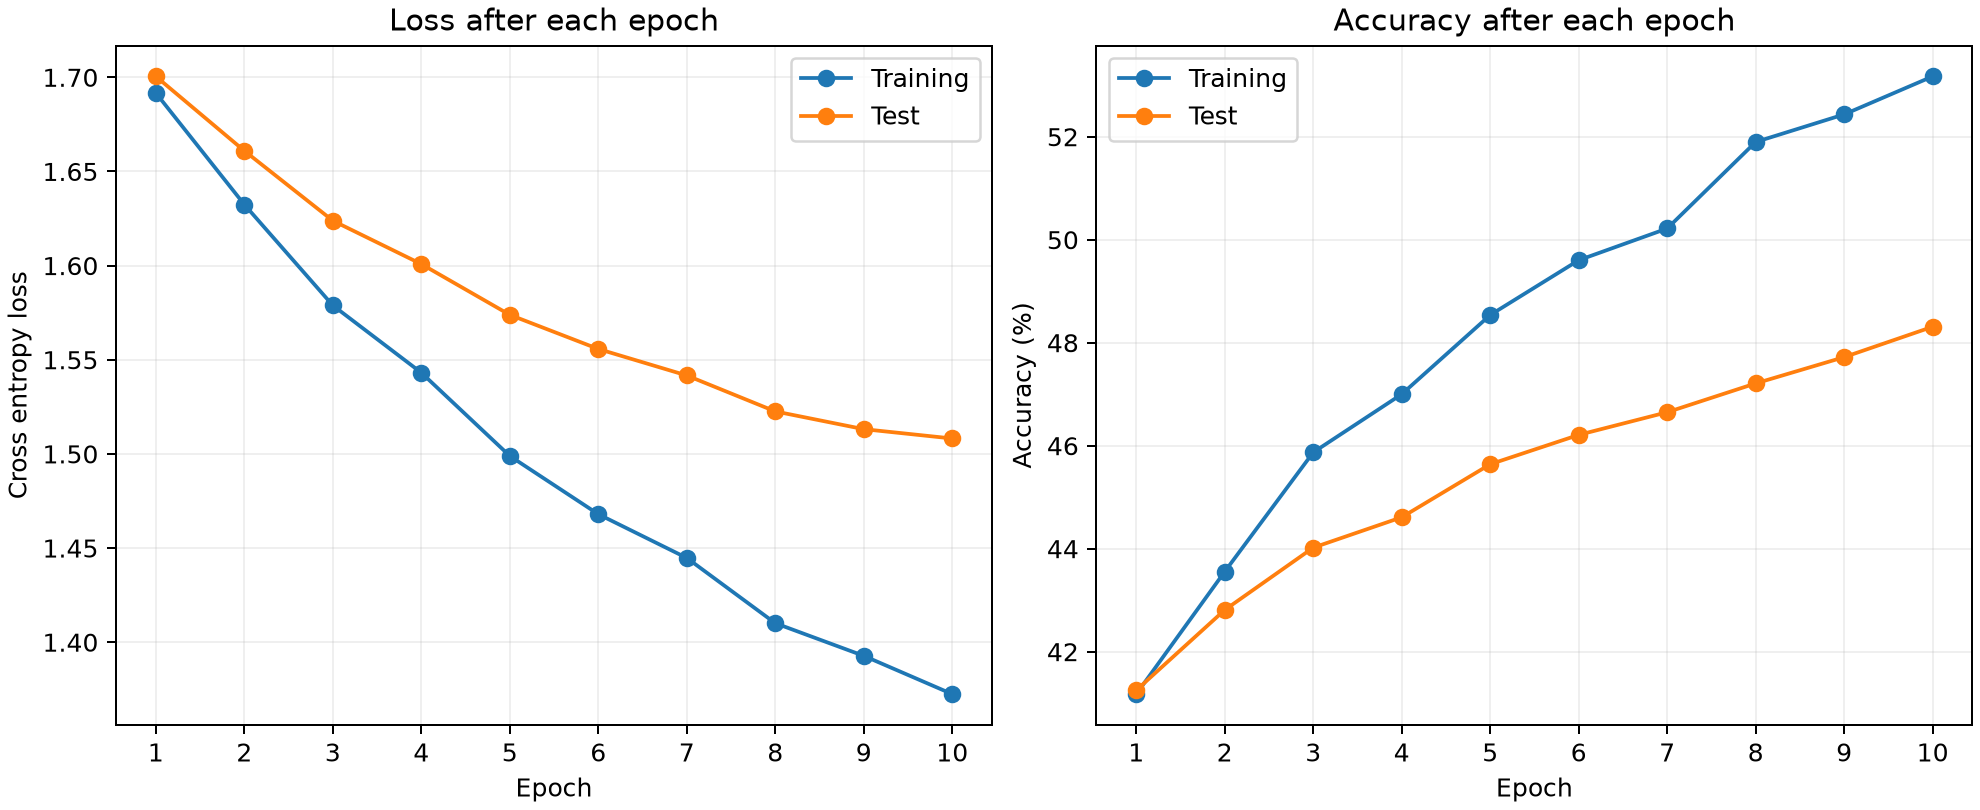

In [8]:
from IPython.display import HTML, Image, display

rows = "".join(f"<tr><td>{r['epoch']}</td><td>{r['train_loss']:.4f}</td><td>{r['test_loss']:.4f}</td><td>{r['train_accuracy']:.2f}</td><td>{r['test_accuracy']:.2f}</td></tr>" for r in result["history"])
display(HTML("<table><tr><th>Epoch</th><th>Training loss</th><th>Test loss</th><th>Training accuracy %</th><th>Test accuracy %</th></tr>" + rows + "</table>"))
display(Image(filename=str(ROOT / "results/q1/training_curve.png"), width=760))


After 10 epochs the training accuracy is 53.17% and the test accuracy is 48.31%. The training loss is 1.3724 and the test loss is 1.5082. Both losses decrease during training and both accuracies increase

The final training accuracy is 4.86 percentage points higher than the test accuracy. Test loss keeps falling until the final epoch so the curves do not show a clear start of overfitting. The network uses flattened image values and does not use convolution layers

A separate small batch check compared all four manual gradients with PyTorch's automatic calculation and agreed within floating point precision. Automatic backpropagation was used only for that check and was not used to train this model